## Clustering

Utilizar los siguientes modelos de clustering:

```python
'''
Importaciones de modelos para clustering
'''
from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
from sklearn.cluster import DBSCAN
from sklearn.cluster import Birch
from sklearn.cluster import AgglomerativeClustering
```

#### Parte 1:
Mostrar los datos sin trabajar y después mostrar los datos ya trabajados

Para clusterig:
- Mall Customers
- Wholesale customers
- Seeds Dataset

#### Parte 2:
Mostrar los datos sin trabajar y después mostrar los datos ya trabajados

Para clustering:

| Dataset                              | Después de aplicar Clustering |
| ------------------------------------ | ----------------------------- |
| Wine Quality                         | Regresión y clasificación     |
| Online Shoppers Purchasing Intention | Clasificación                 |
| Student Performance                  | Regresión                     |


In [3]:
"""
Importar modelos de clustering
"""

from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
from sklearn.cluster import DBSCAN
from sklearn.cluster import Birch
from sklearn.cluster import AgglomerativeClustering

"""
Importar un modelo de regresión y clasificación
"""

from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPClassifier

In [4]:
"""
Importar y cargar datasets
"""

import kagglehub
import pandas as pd
import os
from sklearn.datasets import fetch_openml
from ucimlrepo import fetch_ucirepo

wholesale = fetch_openml(name='wholesale-customers', version=1, as_frame=True, parser='auto')
df_wholesale = wholesale.frame

seeds = fetch_openml(name='seeds', version=1, as_frame=True, parser='auto')
df_seeds = seeds.frame

wine_quality = fetch_openml(name='wine-quality-red', version=1, as_frame=True, parser='auto')
df_wine = wine_quality.frame

shoppers_data = fetch_ucirepo(id=468)
df_shoppers = shoppers_data.data.original

student_data = fetch_ucirepo(id=320)
df_student = student_data.data.original

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
# Carga el archivo CSV en Pandas
csv_path = os.path.join(path, "Mall_Customers.csv")
df_mall = pd.read_csv(csv_path)

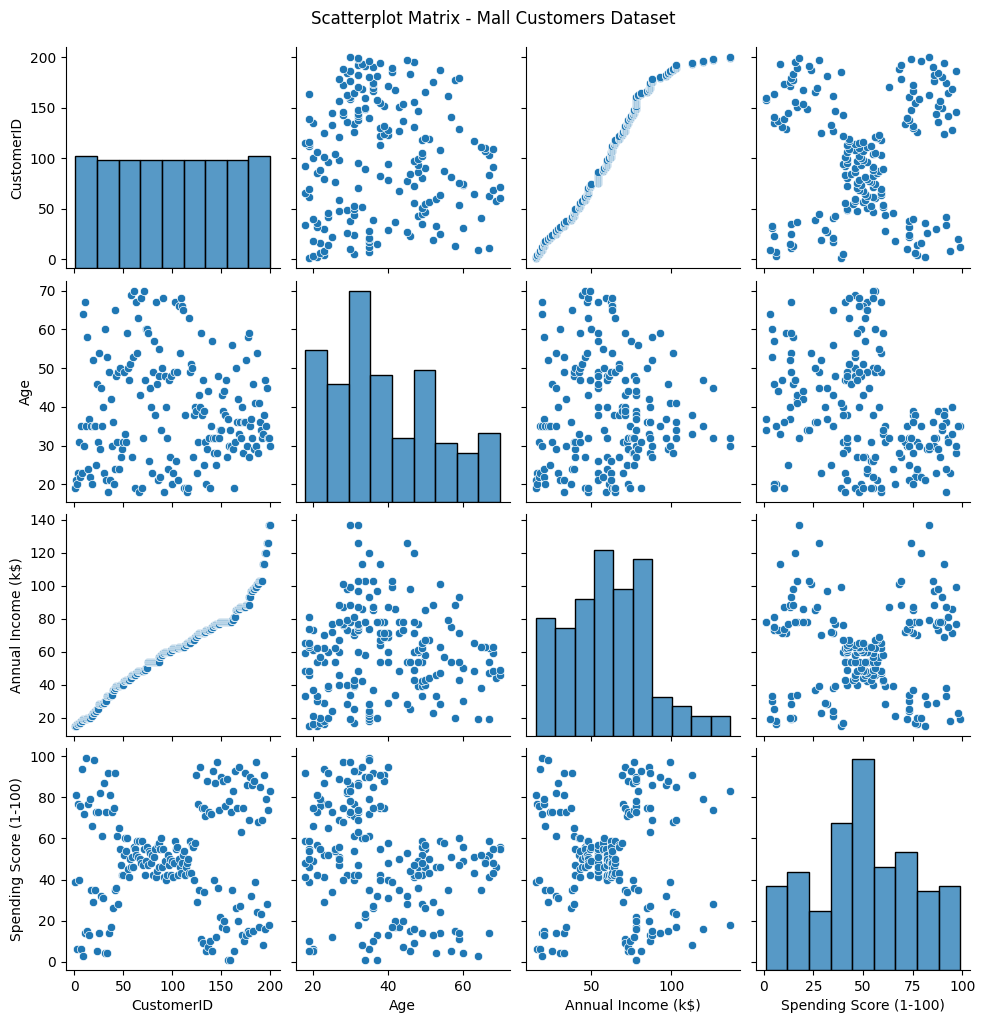

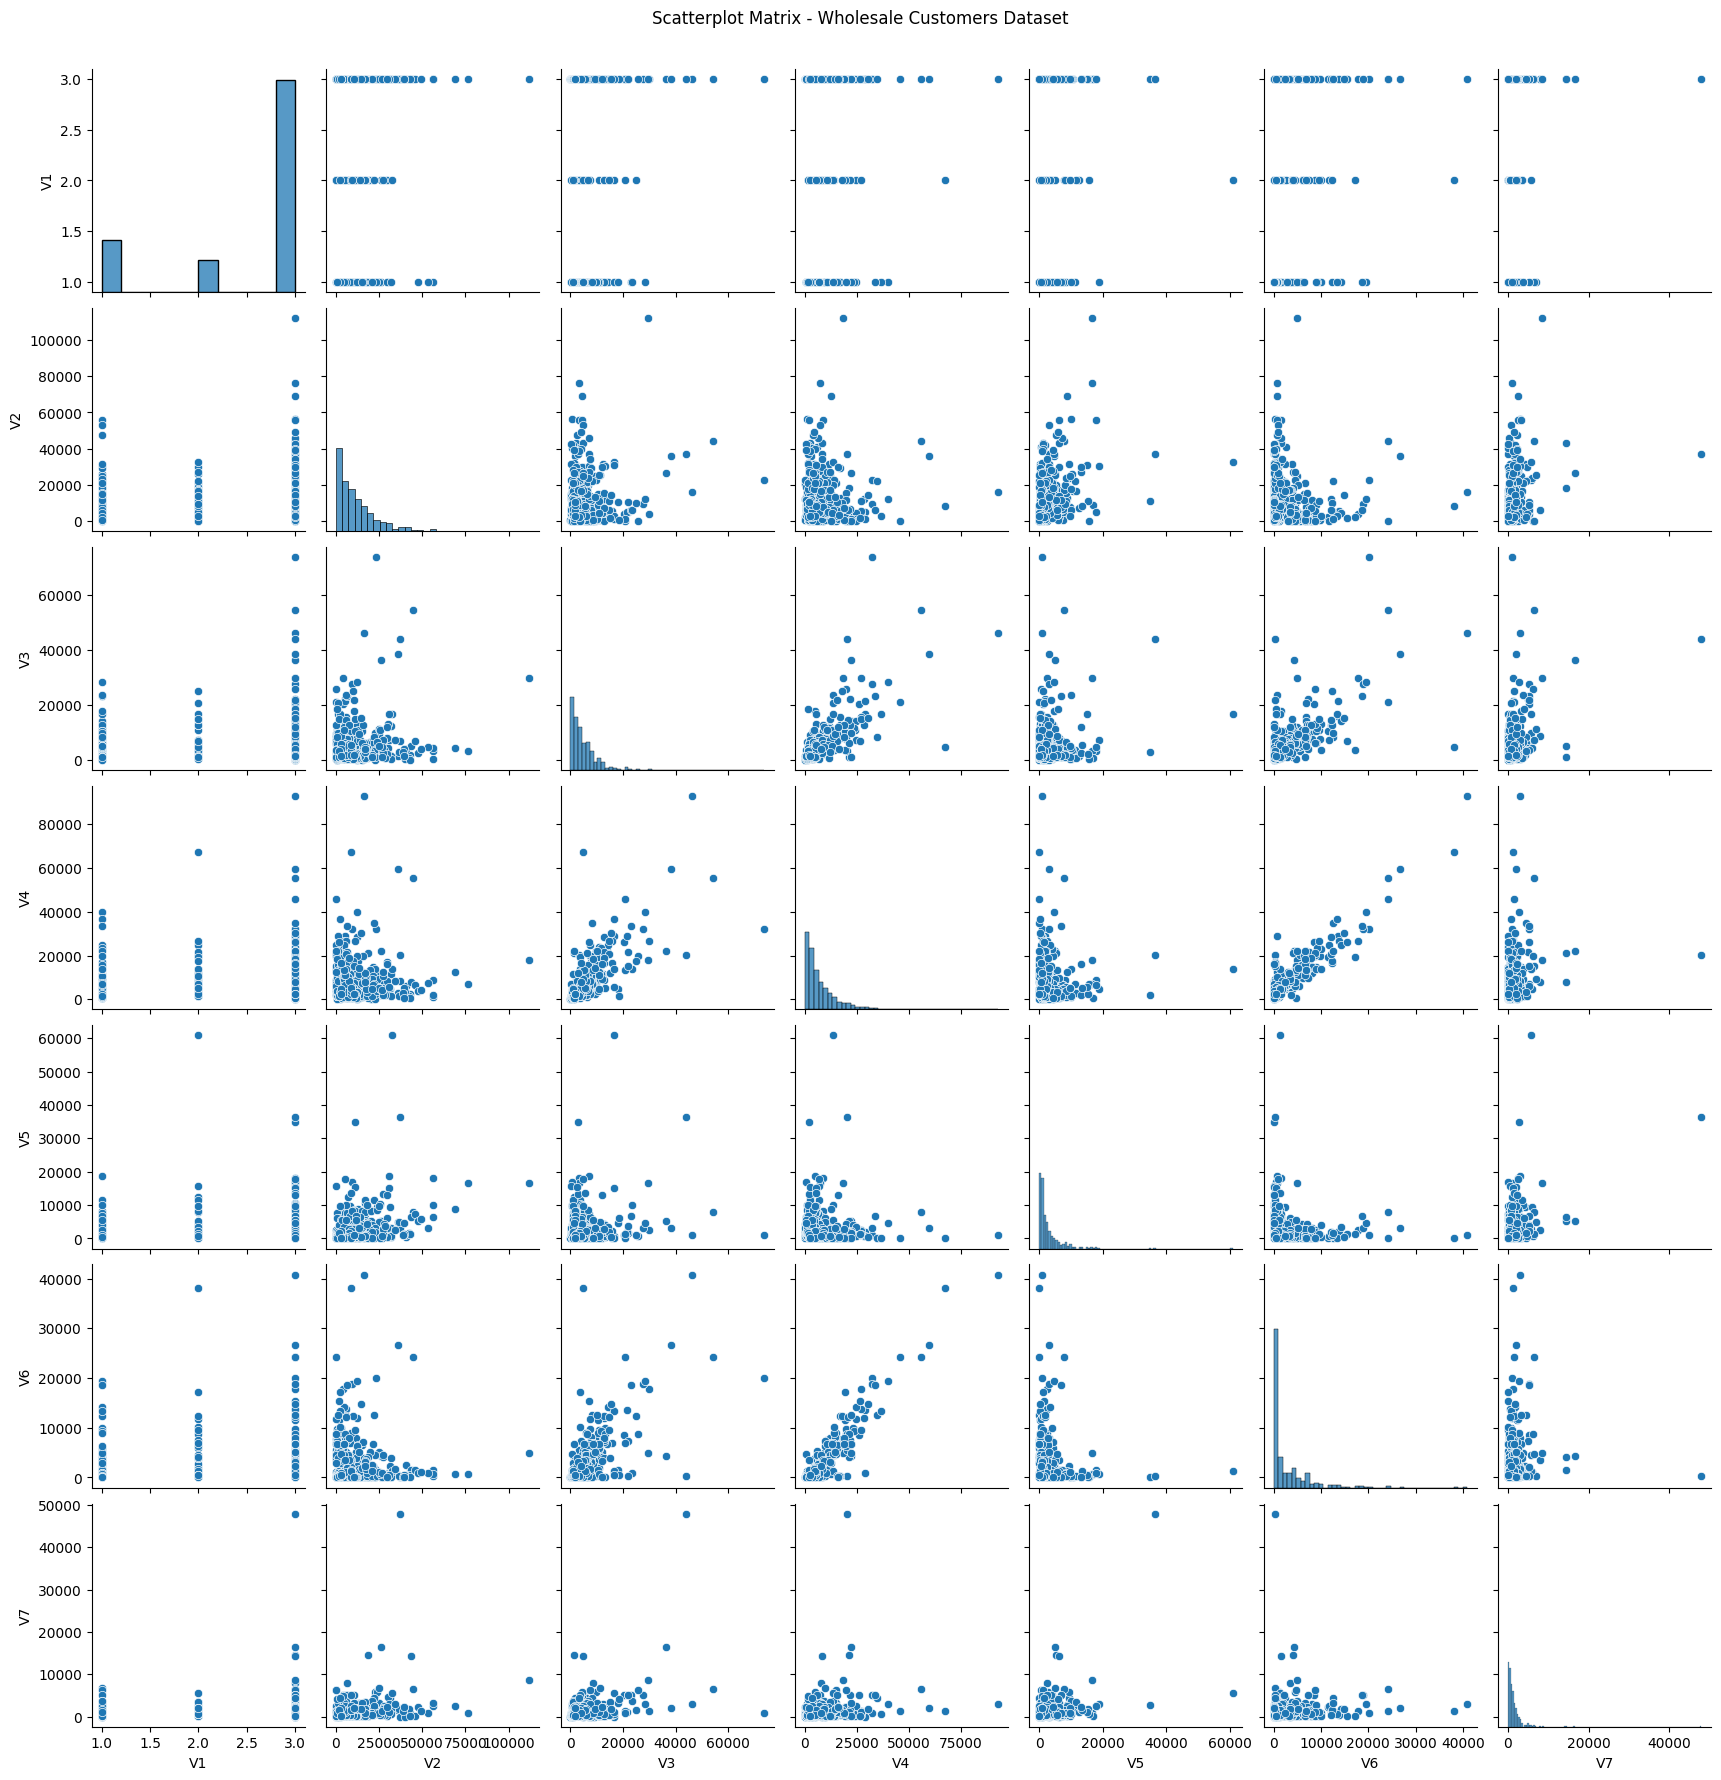

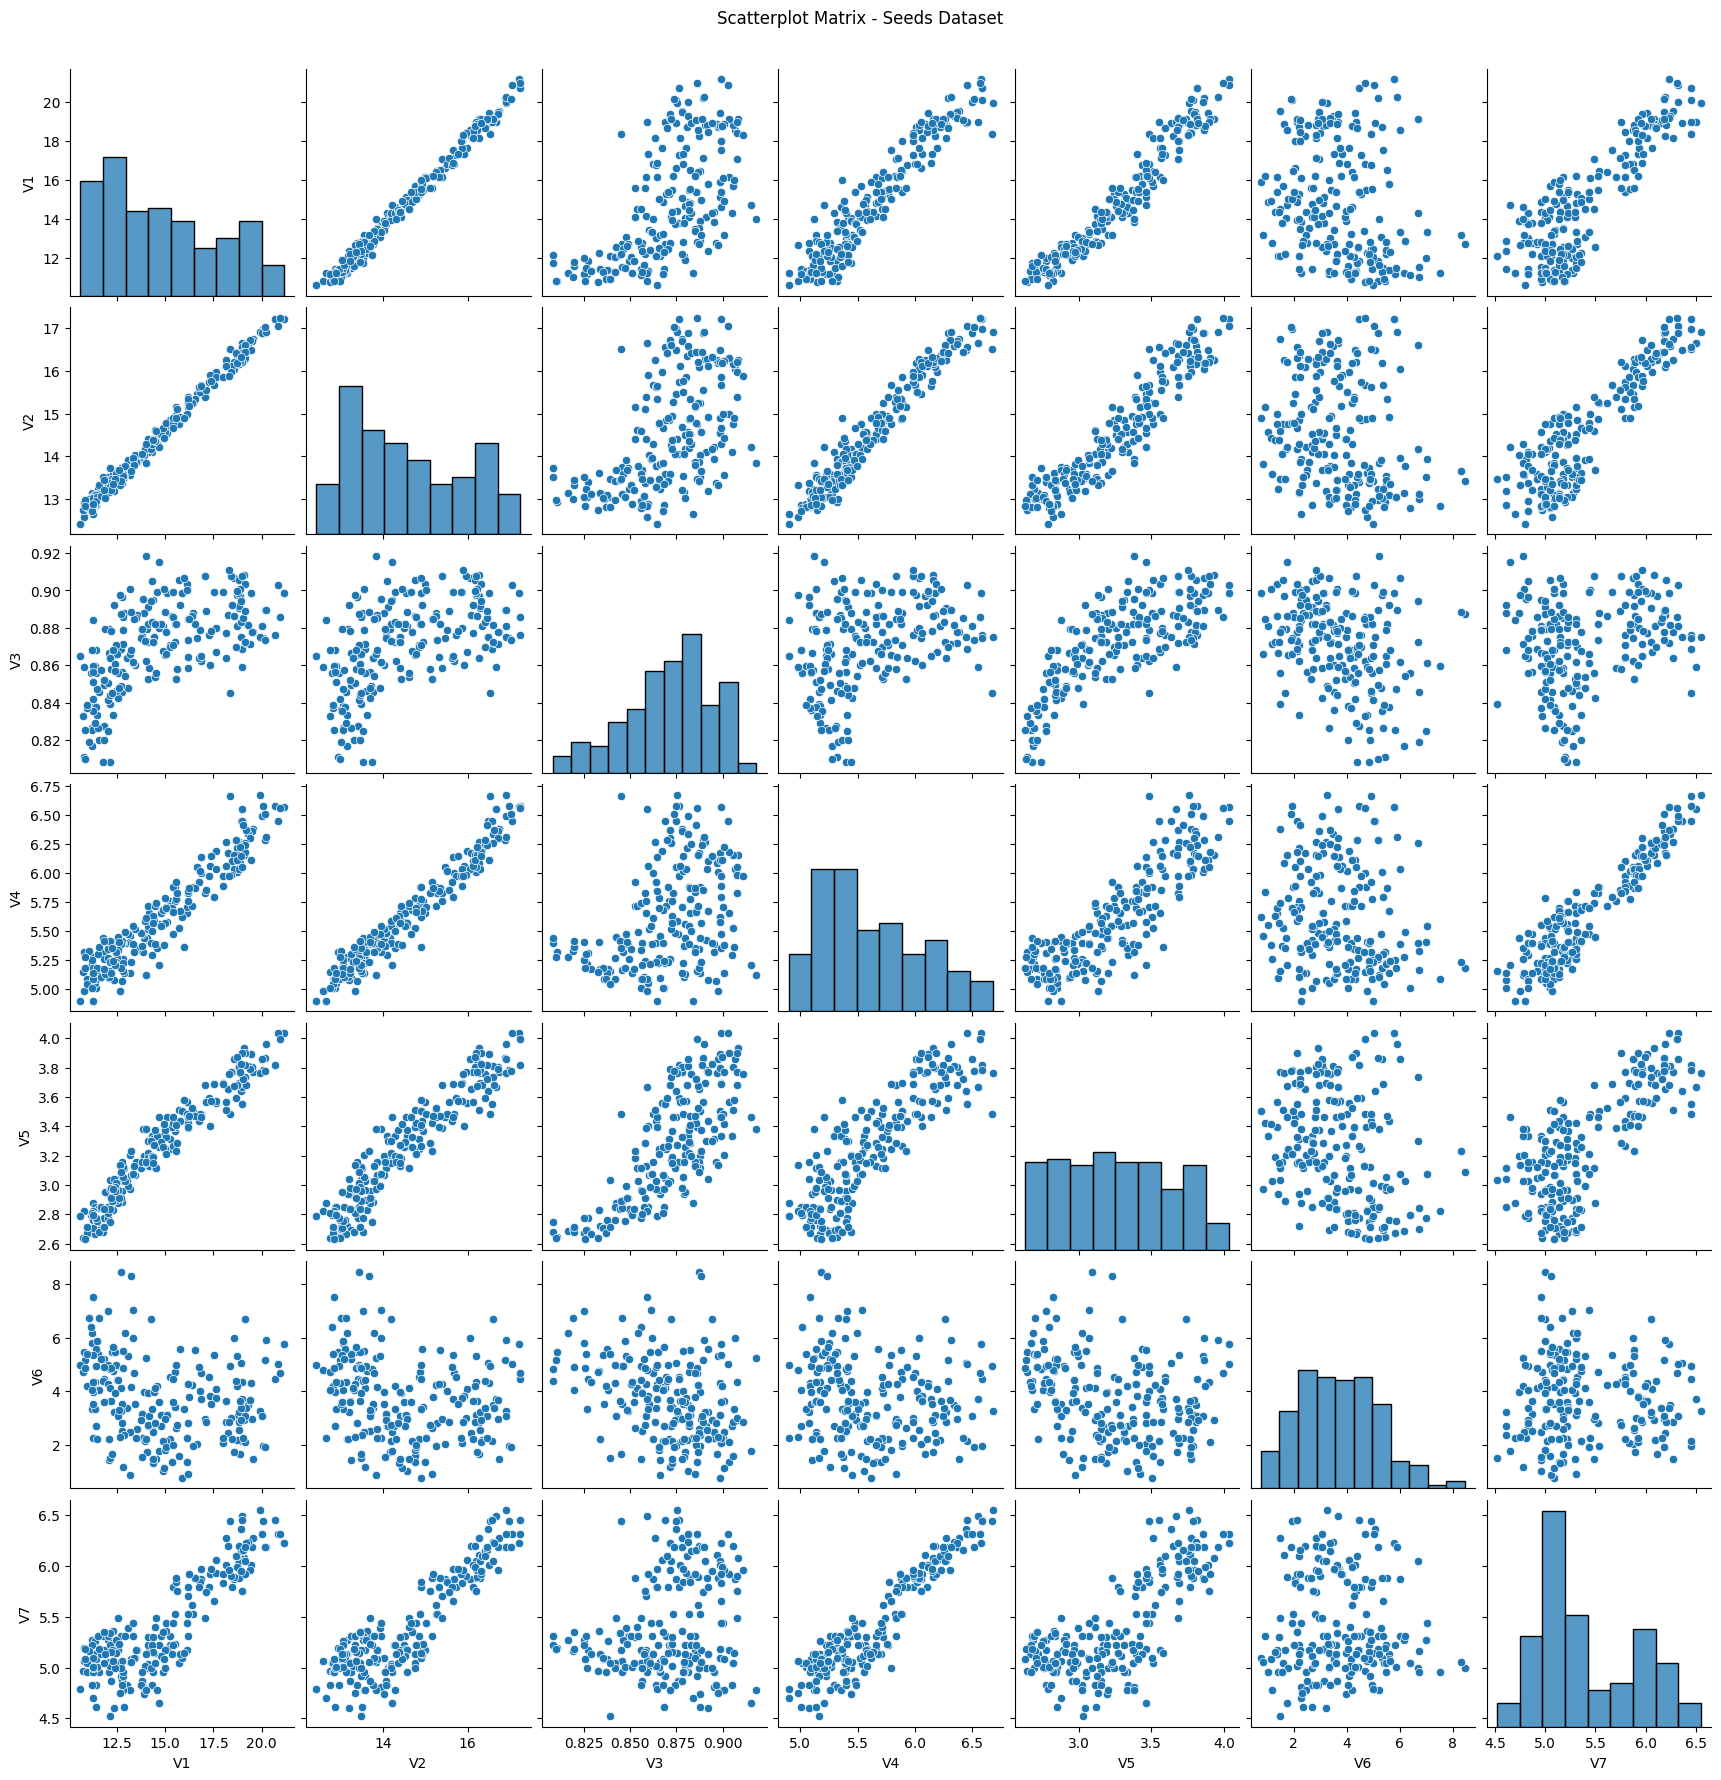

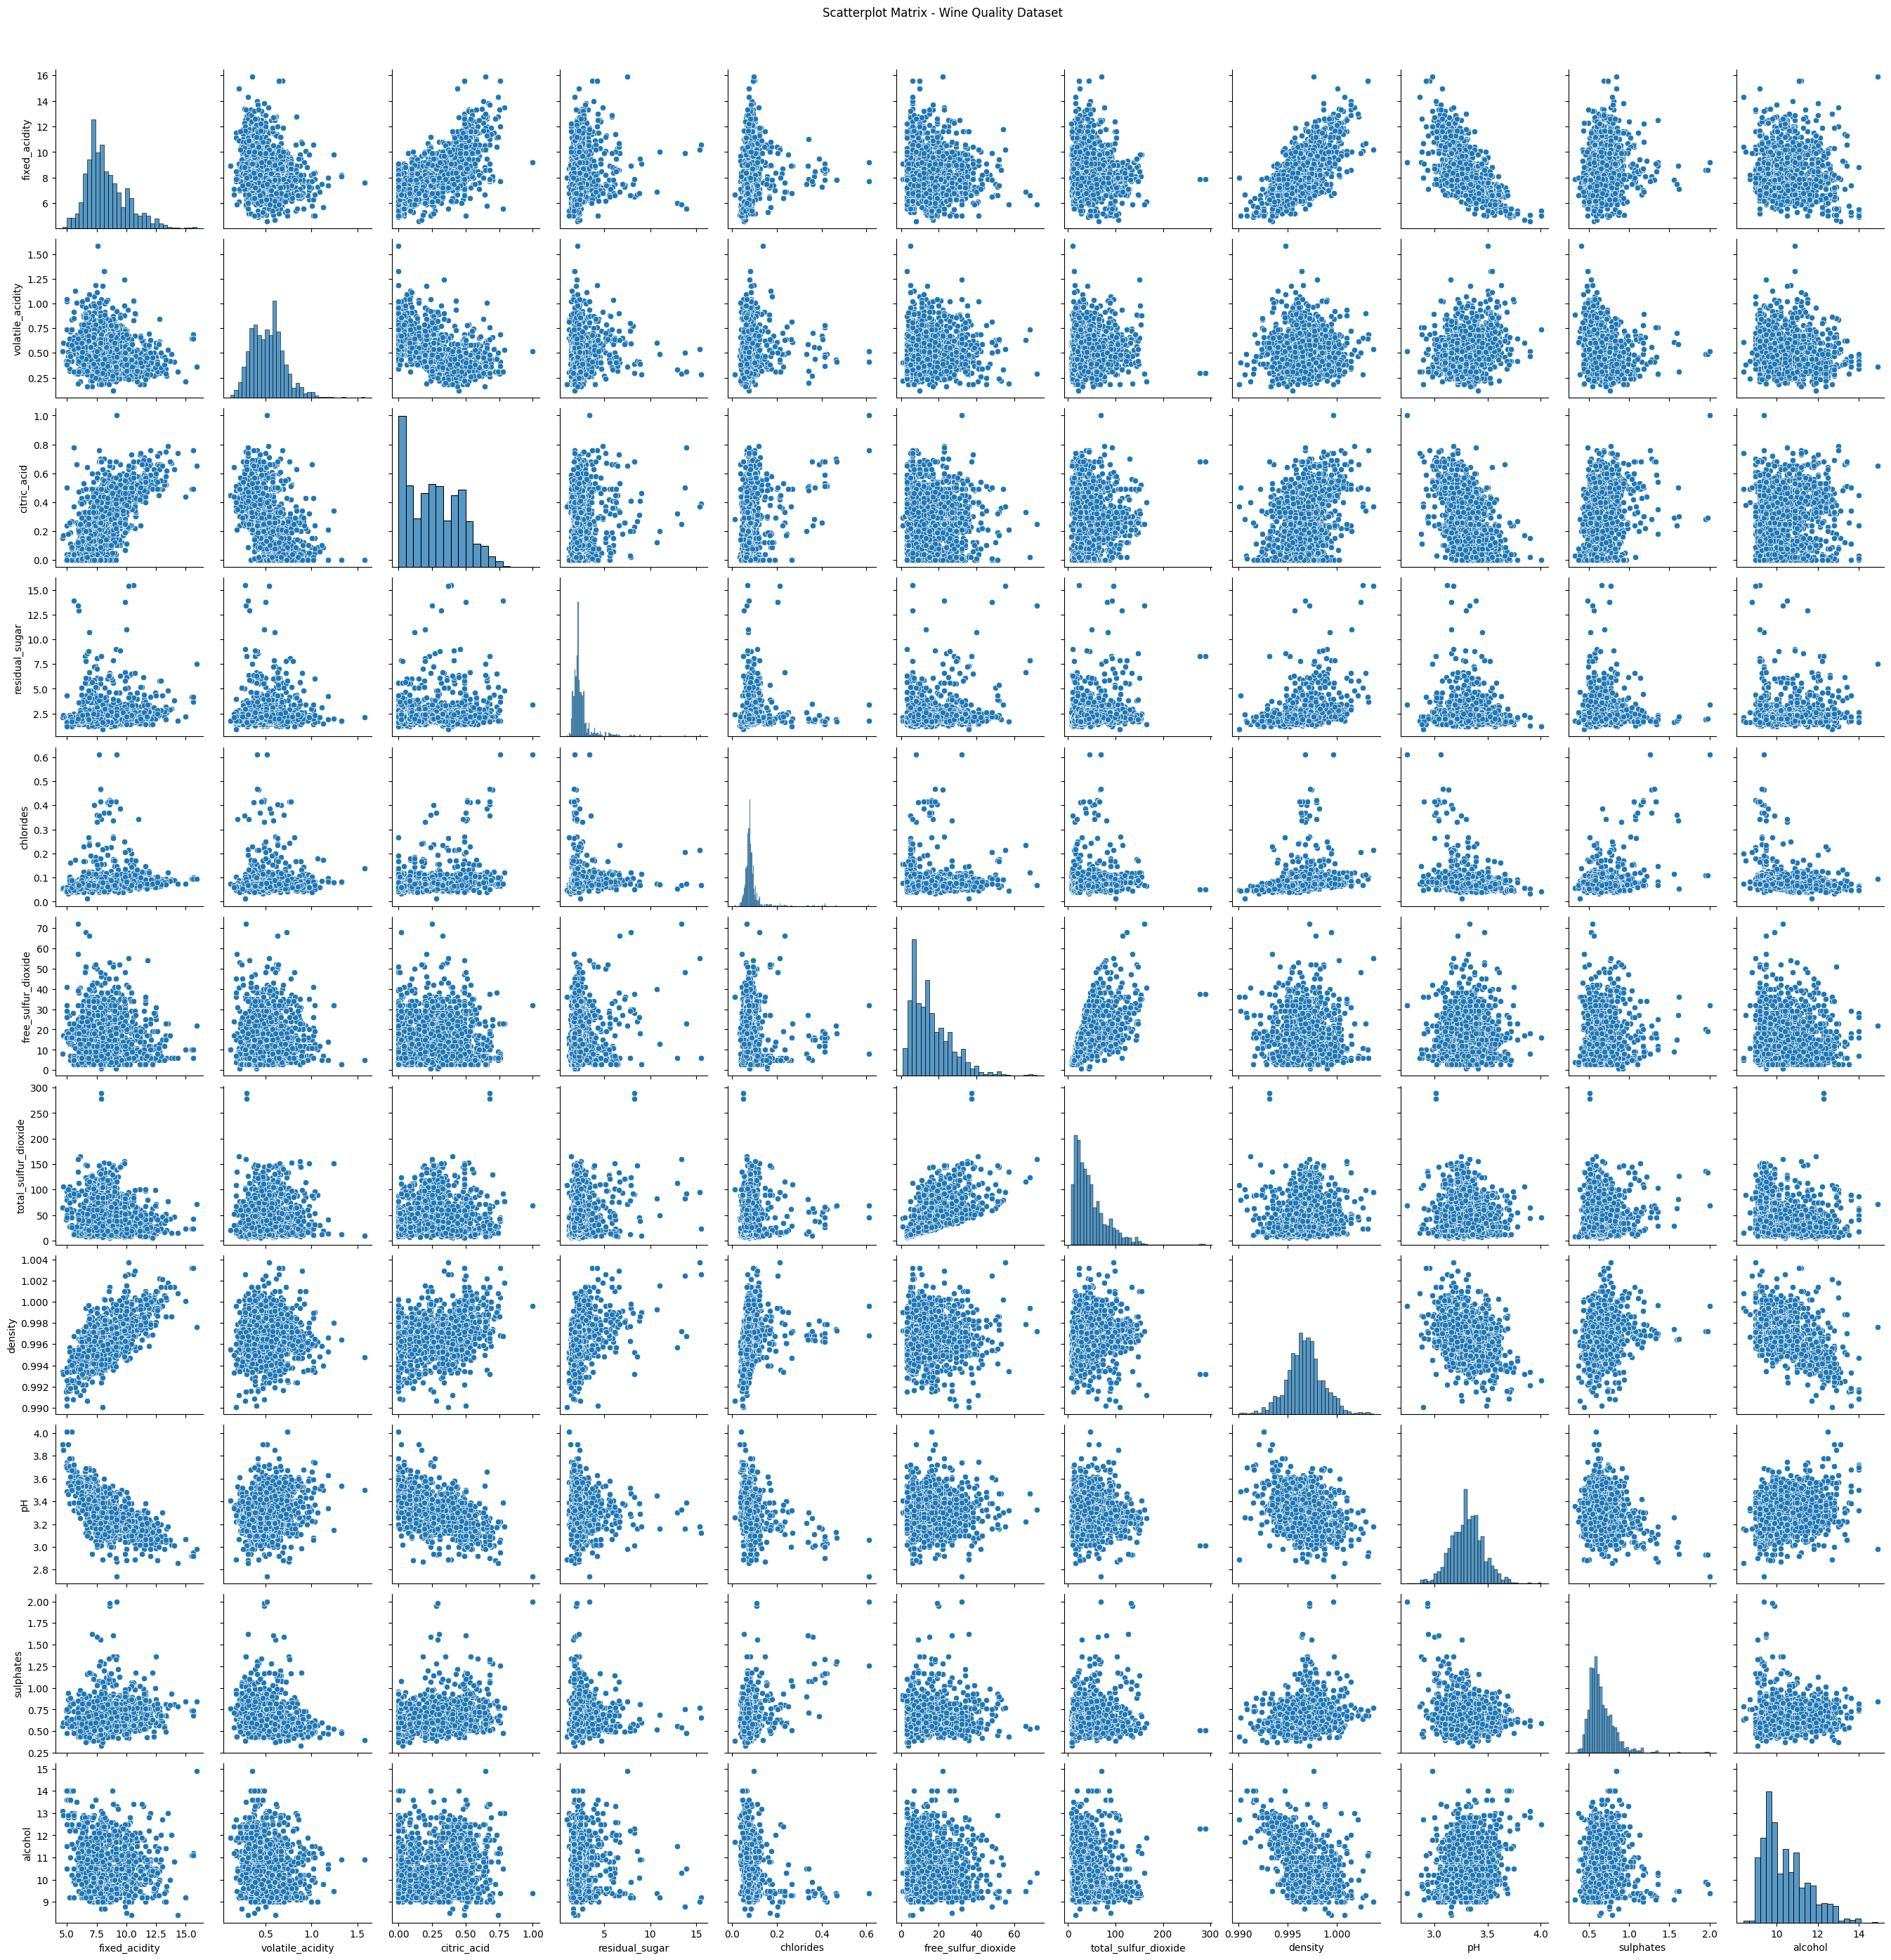

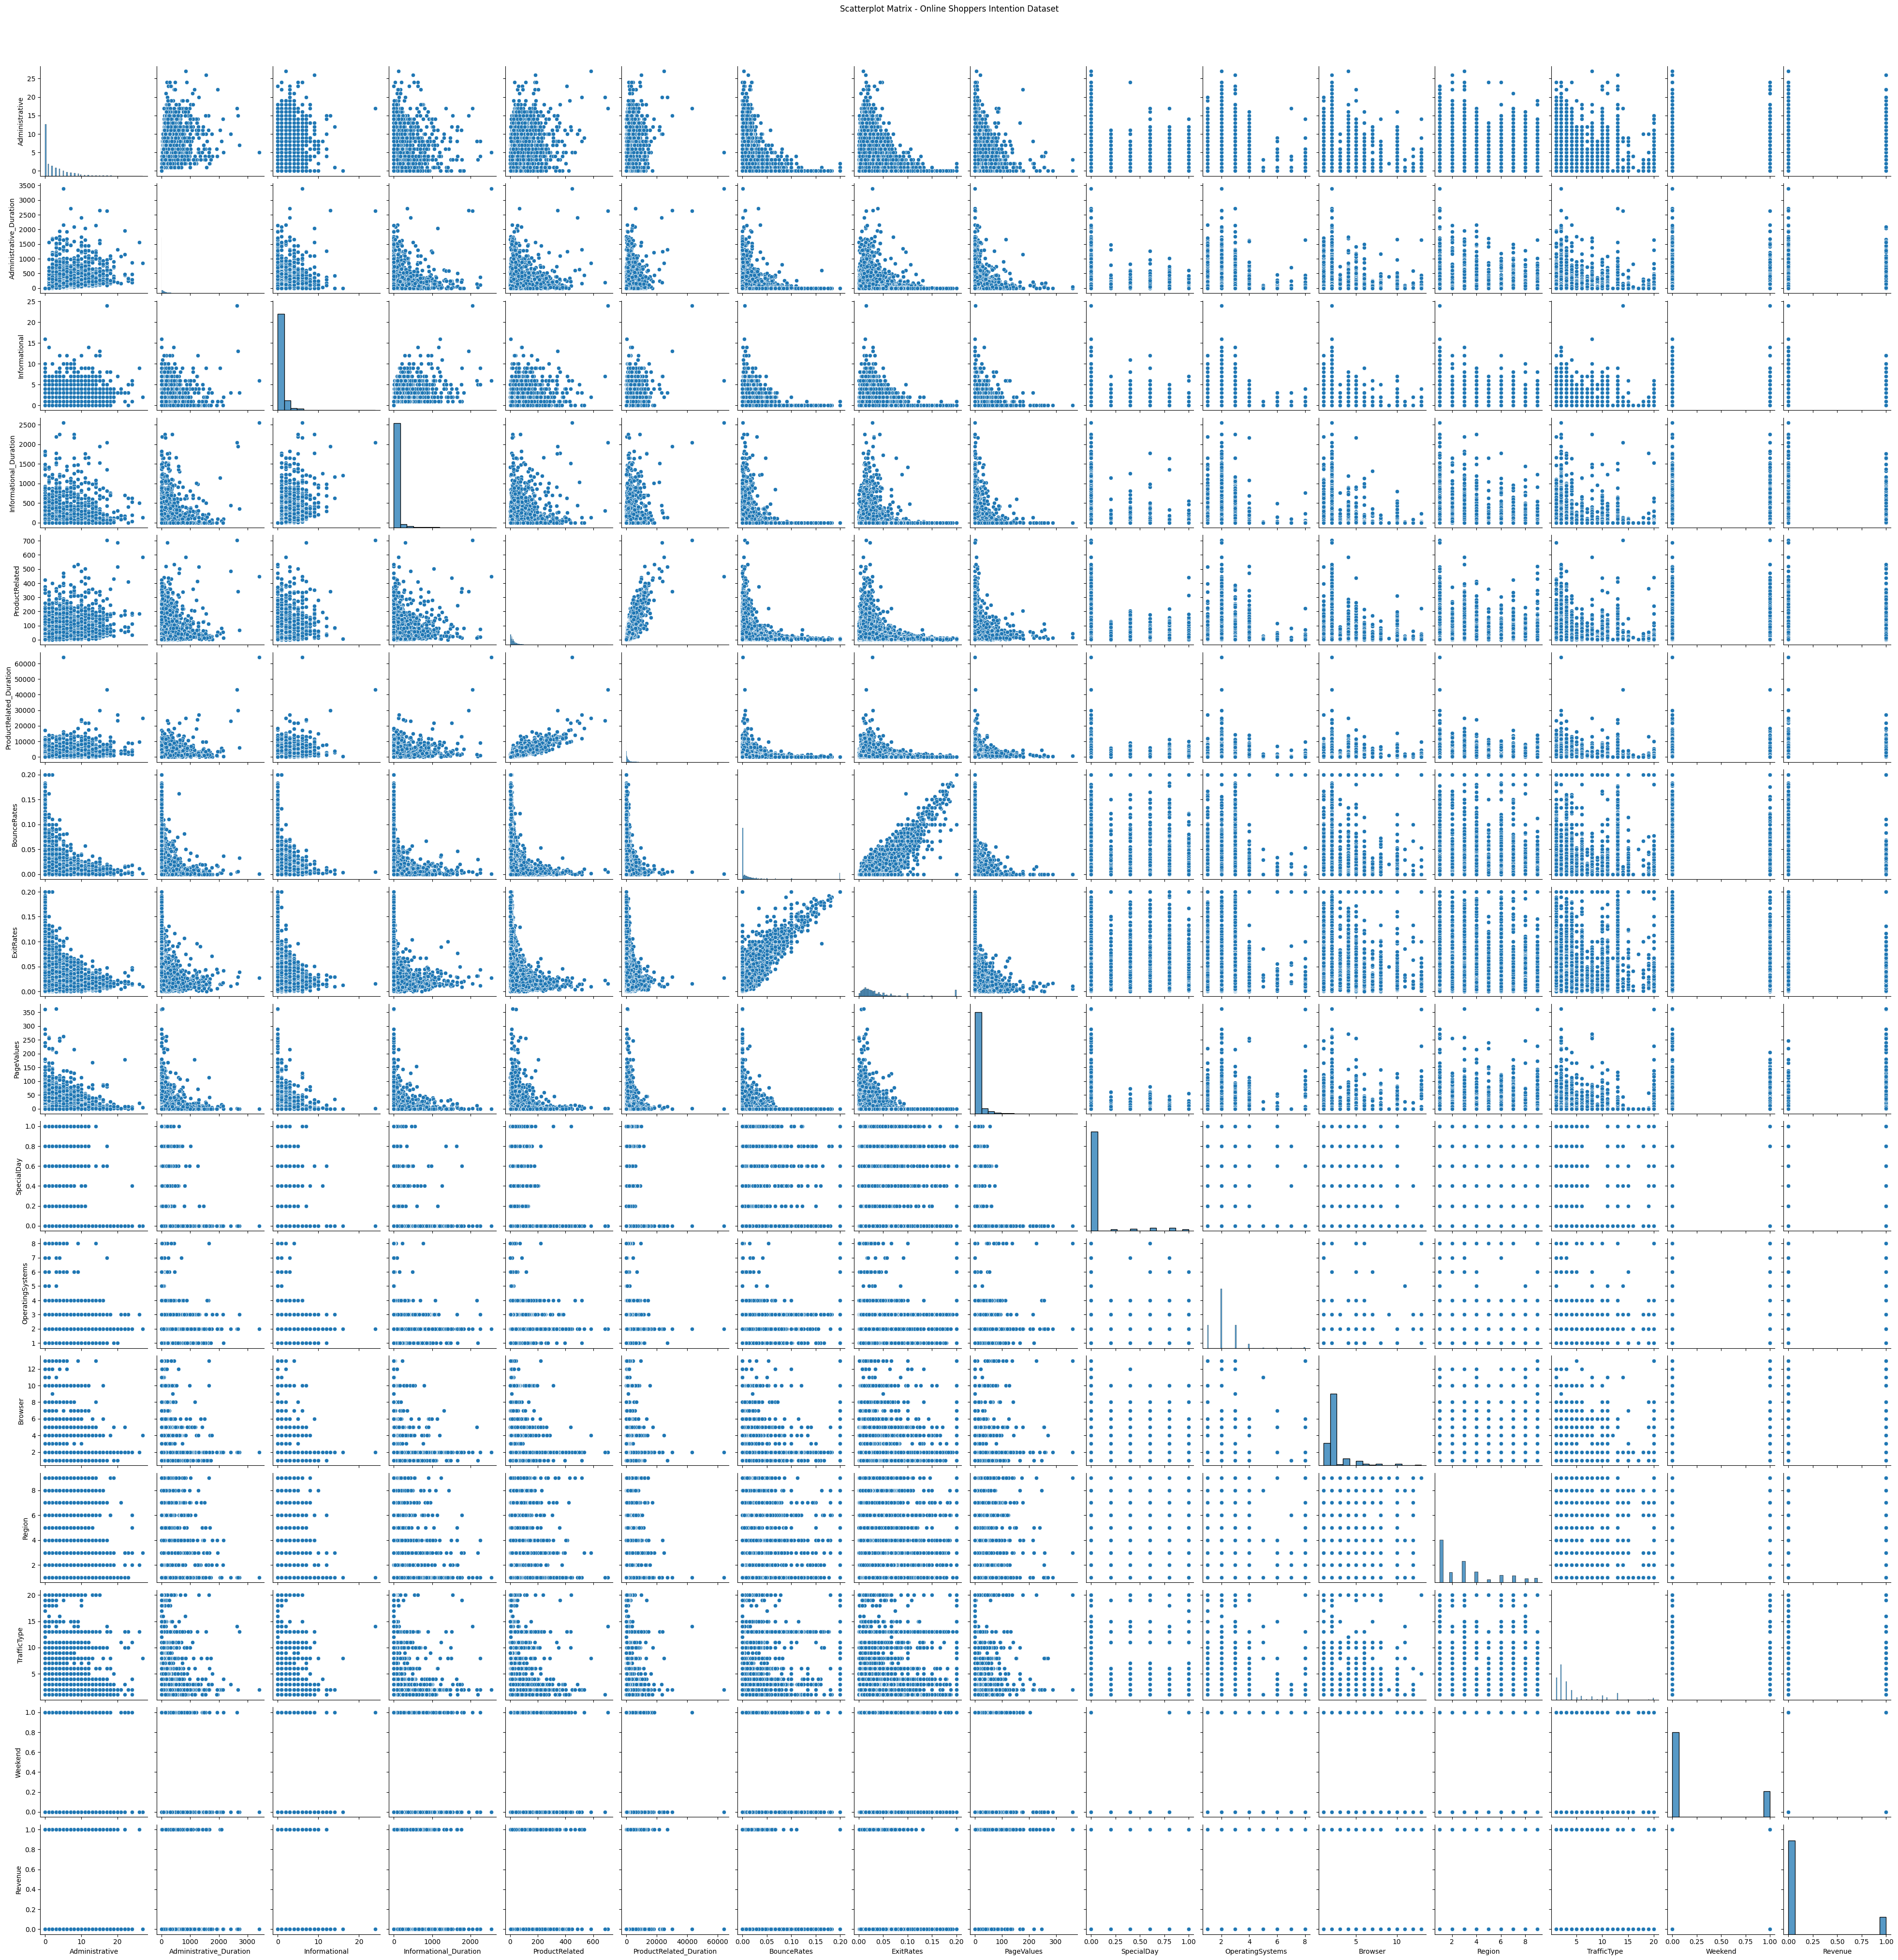

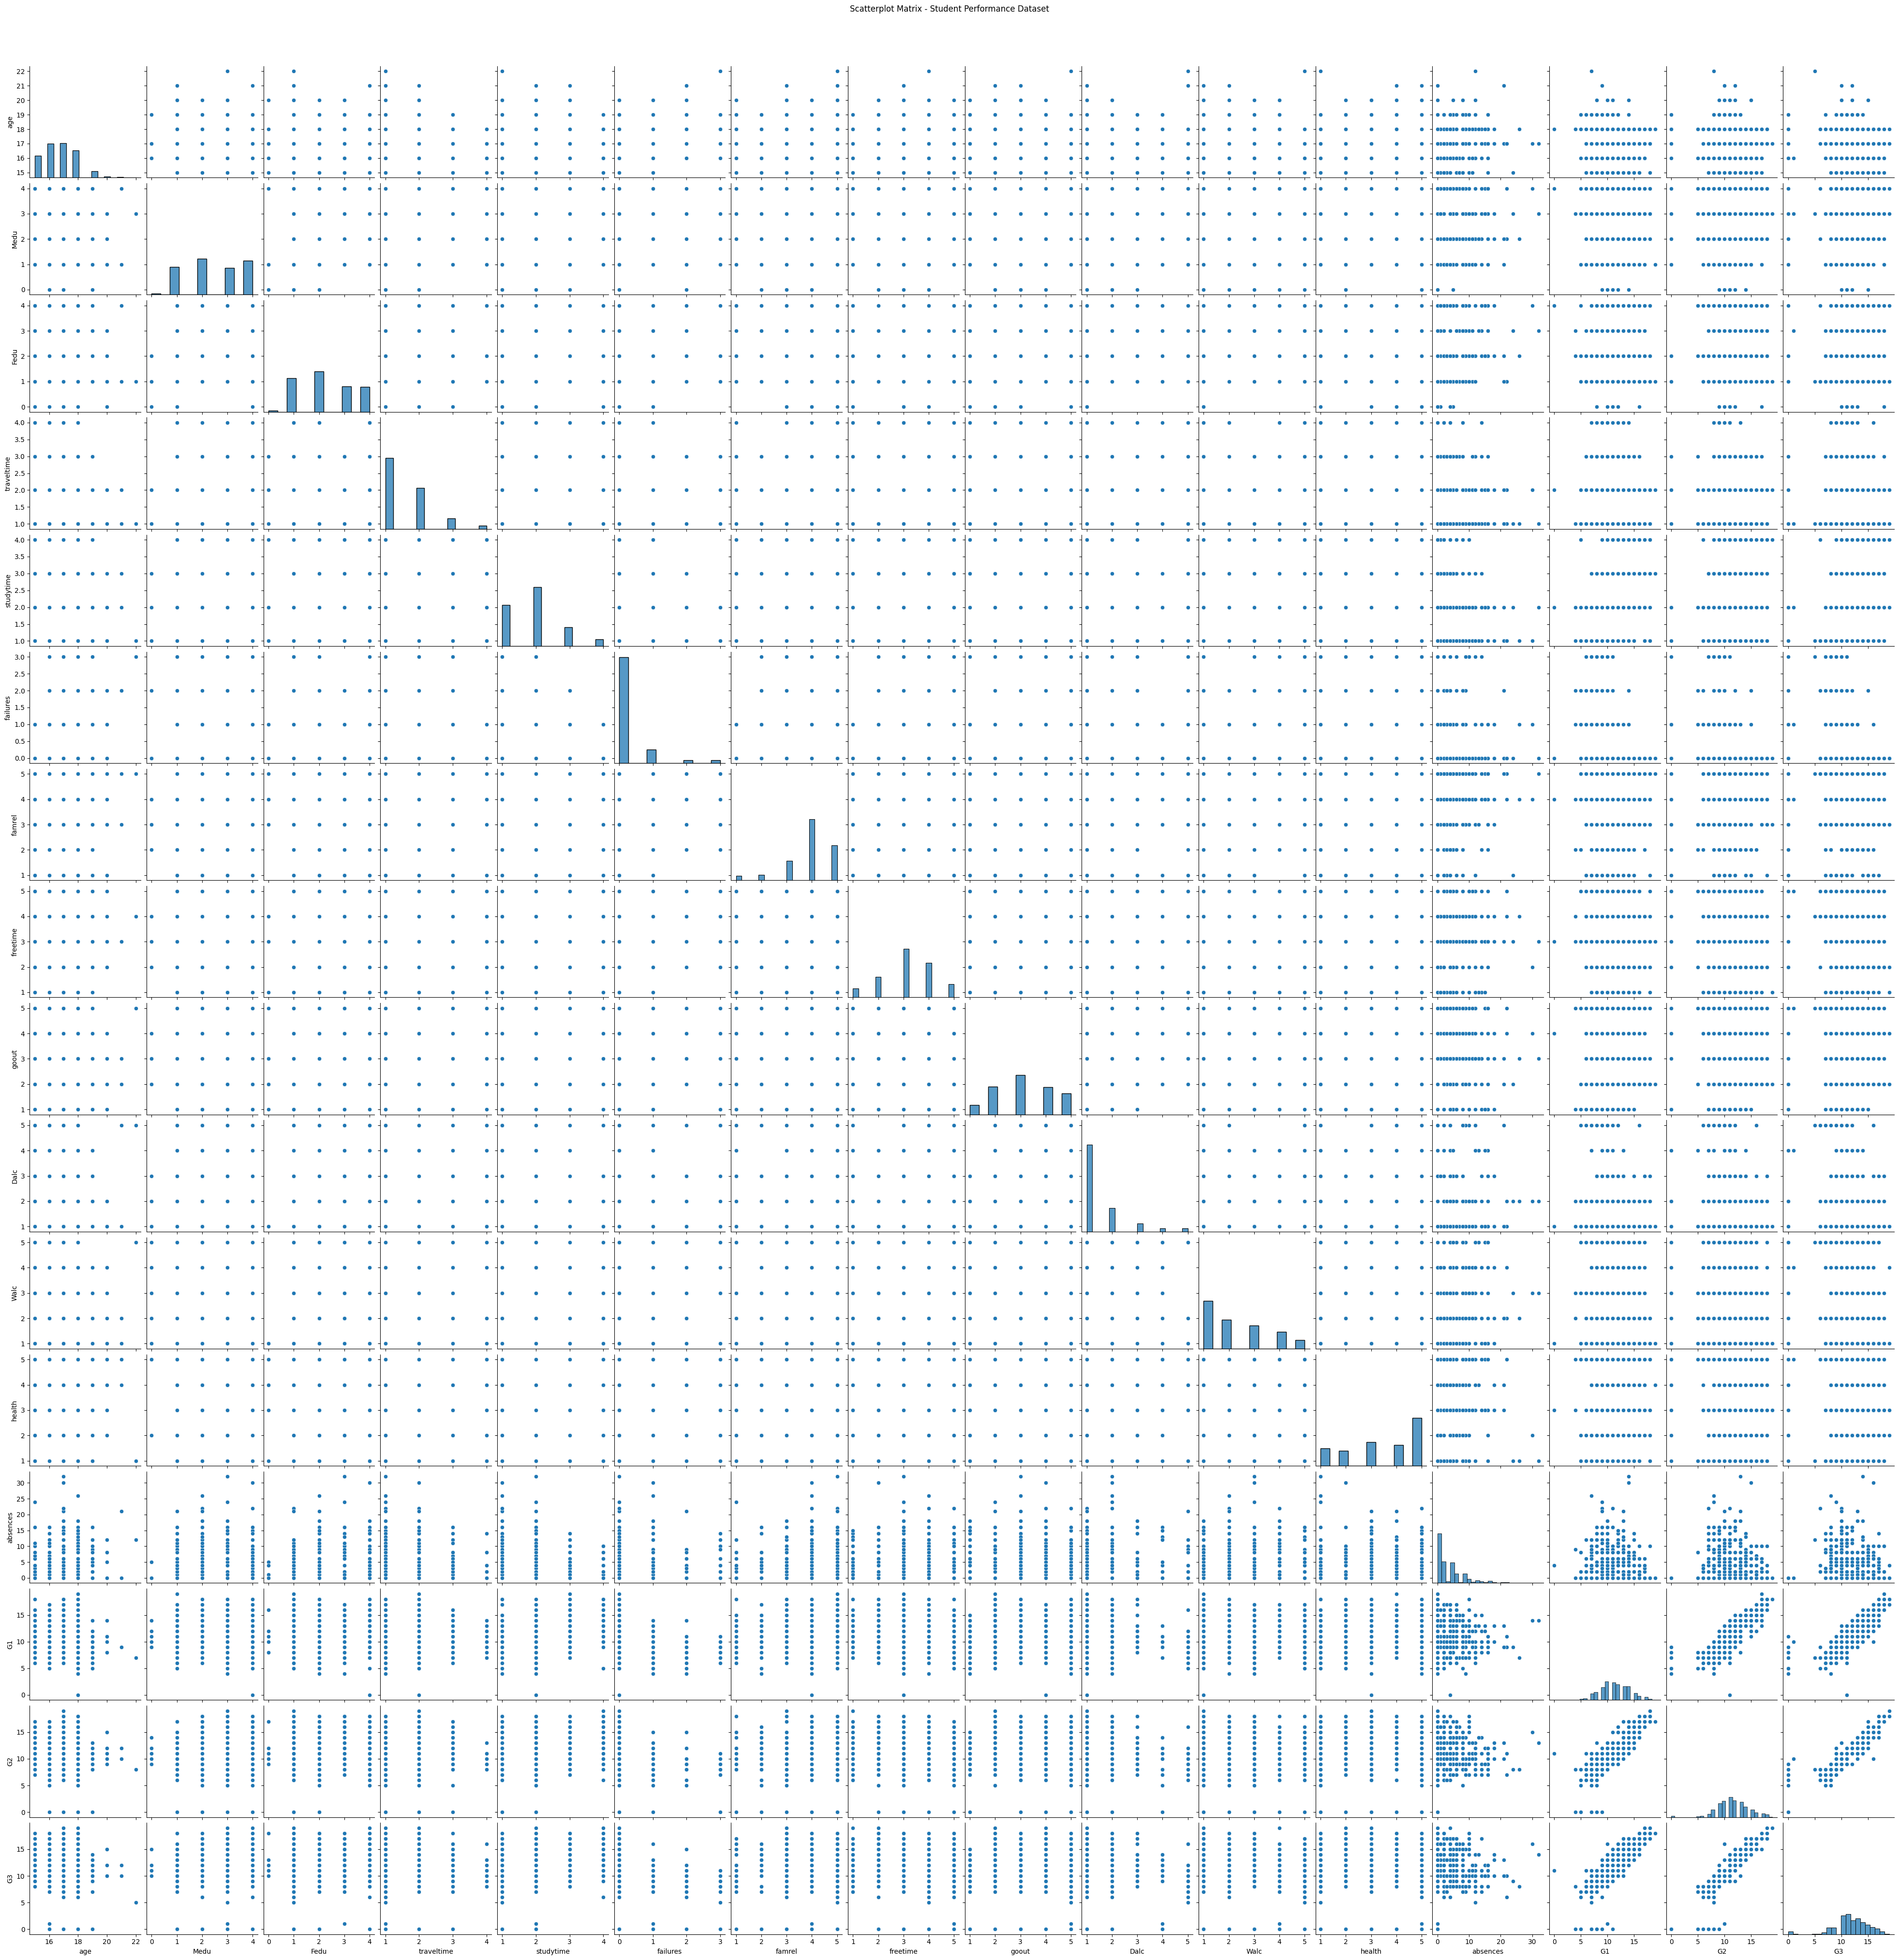

In [5]:
"""
Mostrar graficamente los datasets sin procesar con scatterplot_matrix
"""

import matplotlib.pyplot as plt
import seaborn as sns

def plot_dataset(df, title):

    # Crear un scatterplot matrix
    sns.pairplot(df)
    plt.suptitle(f"Scatterplot Matrix - {title}", y=1.02)
    plt.show()

plot_dataset(df_mall, "Mall Customers Dataset")
plot_dataset(df_wholesale, "Wholesale Customers Dataset")
plot_dataset(df_seeds, "Seeds Dataset")
plot_dataset(df_wine, "Wine Quality Dataset")
plot_dataset(df_shoppers, "Online Shoppers Intention Dataset")
plot_dataset(df_student, "Student Performance Dataset")


In [6]:
"""
Funcion para aplicar los modelos de clustering para agrupar los datos y compararlos
"""

from sklearn.preprocessing import StandardScaler

def aplicar_clustering(df, n_clusters=5, columnas_ignorar=None, eps=0.5, min_samples=5):
    """
    Preprocesa un DataFrame y le aplica 5 algoritmos de clustering.
    """
    # 1. Hacer una copia para no alterar el dataset original
    datos = df.copy()
    
    # 2. Eliminar columnas que no aportan al agrupamiento (ej. IDs)
    if columnas_ignorar:
        if isinstance(columnas_ignorar, str):
            columnas_ignorar = [columnas_ignorar]
        # Borramos las columnas solo si existen en el DataFrame
        columnas_existentes = [col for col in columnas_ignorar if col in datos.columns]
        datos = datos.drop(columns=columnas_existentes)
        
    # 3. Eliminar filas con valores nulos
    datos = datos.dropna()
    
    # 4. Convertir variables categóricas (texto) a numéricas automáticamente
    # Esto es vital para datasets como "Student Performance" o "Online Shoppers"
    datos_procesados = pd.get_dummies(datos, drop_first=True)
    
    # 5. Escalar los datos (Misma escala para todas las variables)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(datos_procesados)
    
    # 6. Configurar los 5 modelos
    modelos = {
        "KMeans": KMeans(n_clusters=n_clusters, random_state=42, n_init='auto'),
        "Spectral": SpectralClustering(n_clusters=n_clusters, random_state=42, affinity='nearest_neighbors'),
        "DBSCAN": DBSCAN(eps=eps, min_samples=min_samples),
        "Birch": Birch(n_clusters=n_clusters),
        "Agglomerative": AgglomerativeClustering(n_clusters=n_clusters)
    }
    
    # 7. Entrenar y predecir
    # Usamos la versión "datos_procesados" para ver fácilmente las variables transformadas
    df_resultados = datos_procesados.copy() 
    
    for nombre, modelo in modelos.items():
        # fit_predict asigna a cada fila el número de su cluster
        df_resultados[f'Cluster_{nombre}'] = modelo.fit_predict(X_scaled)
        
    return df_resultados

In [7]:
"""
Funcion para mostrar los resultados por cada modelo de clustering graficamente con scatterplot coloreando por clusters
"""
import matplotlib.pyplot as plt

def graficar_comparacion(df_resultados, nombre_dataset):
    """
    Toma el DataFrame con los clusters ya calculados y genera 
    5 subgráficos lado a lado para comparar los algoritmos.
    """
    modelos = ['KMeans', 'Spectral', 'DBSCAN', 'Birch', 'Agglomerative']
    
    # Creamos una figura ancha con 1 fila y 5 columnas
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(f'Comparación de Algoritmos de Clustering: {nombre_dataset}', fontsize=16)
    
    # Extraemos los nombres reales de las primeras dos columnas para los ejes
    nombre_col1 = df_resultados.columns[0]
    nombre_col2 = df_resultados.columns[1]
    
    for ax, modelo in zip(axes, modelos):
        columna_cluster = f'Cluster_{modelo}'
        
        # Graficamos usando las posiciones 0 y 1 para evitar errores de nombre
        ax.scatter(df_resultados.iloc[:, 0], 
                   df_resultados.iloc[:, 1], 
                   c=df_resultados[columna_cluster], 
                   cmap='viridis', 
                   s=30, alpha=0.7)
        
        ax.set_title(f'Modelo: {modelo}')
        ax.set_xlabel(nombre_col1)
        
        # Solo le ponemos la etiqueta Y al primer gráfico para no saturar la imagen
        if ax == axes[0]:
            ax.set_ylabel(nombre_col2)
            
    plt.tight_layout()
    plt.show()


#### Parte 1

Aplicando clustering al dataset de Mall Customers...


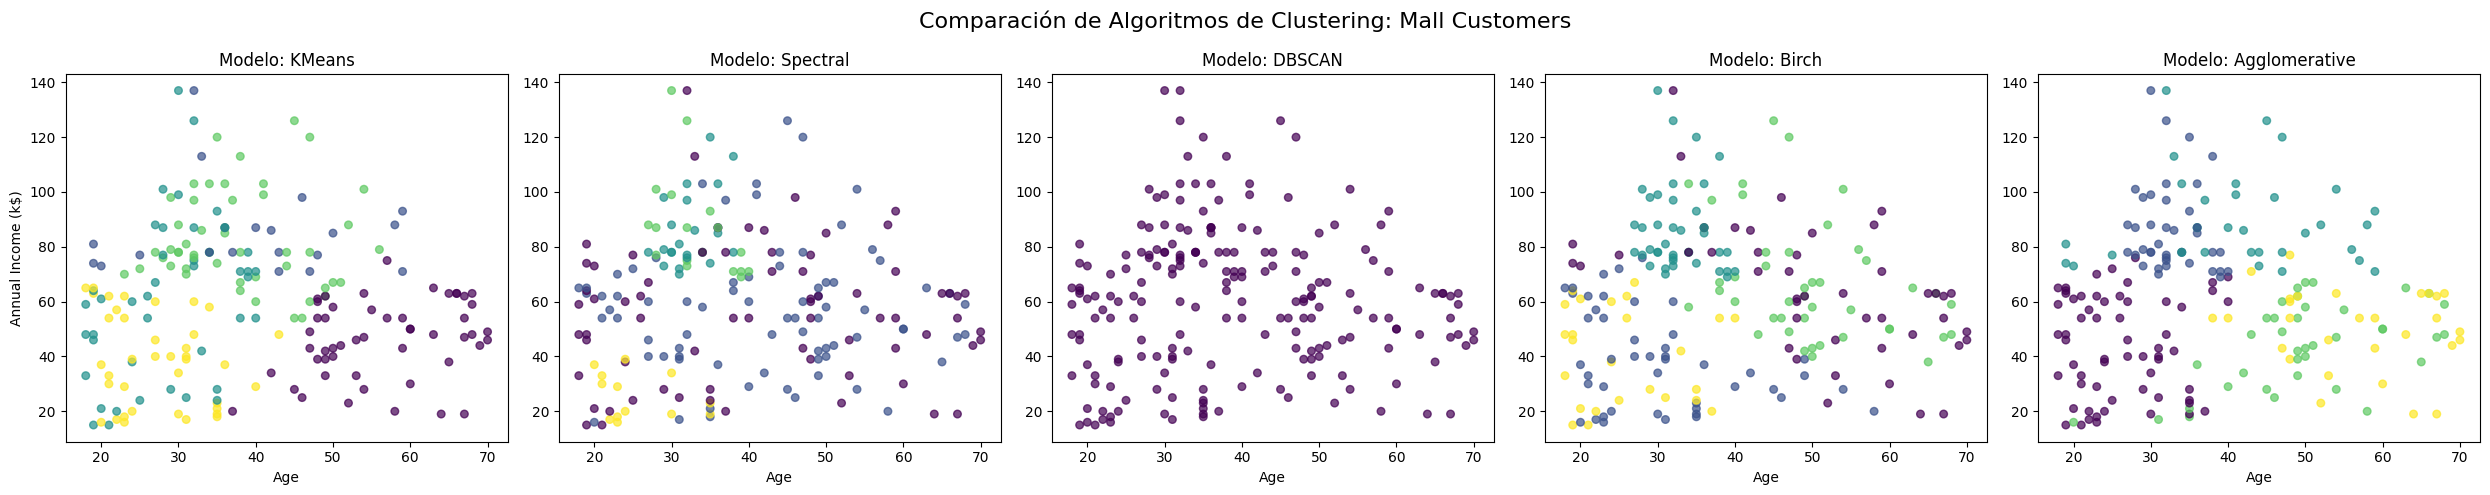

Aplicando clustering al dataset de Wholesale Customers...


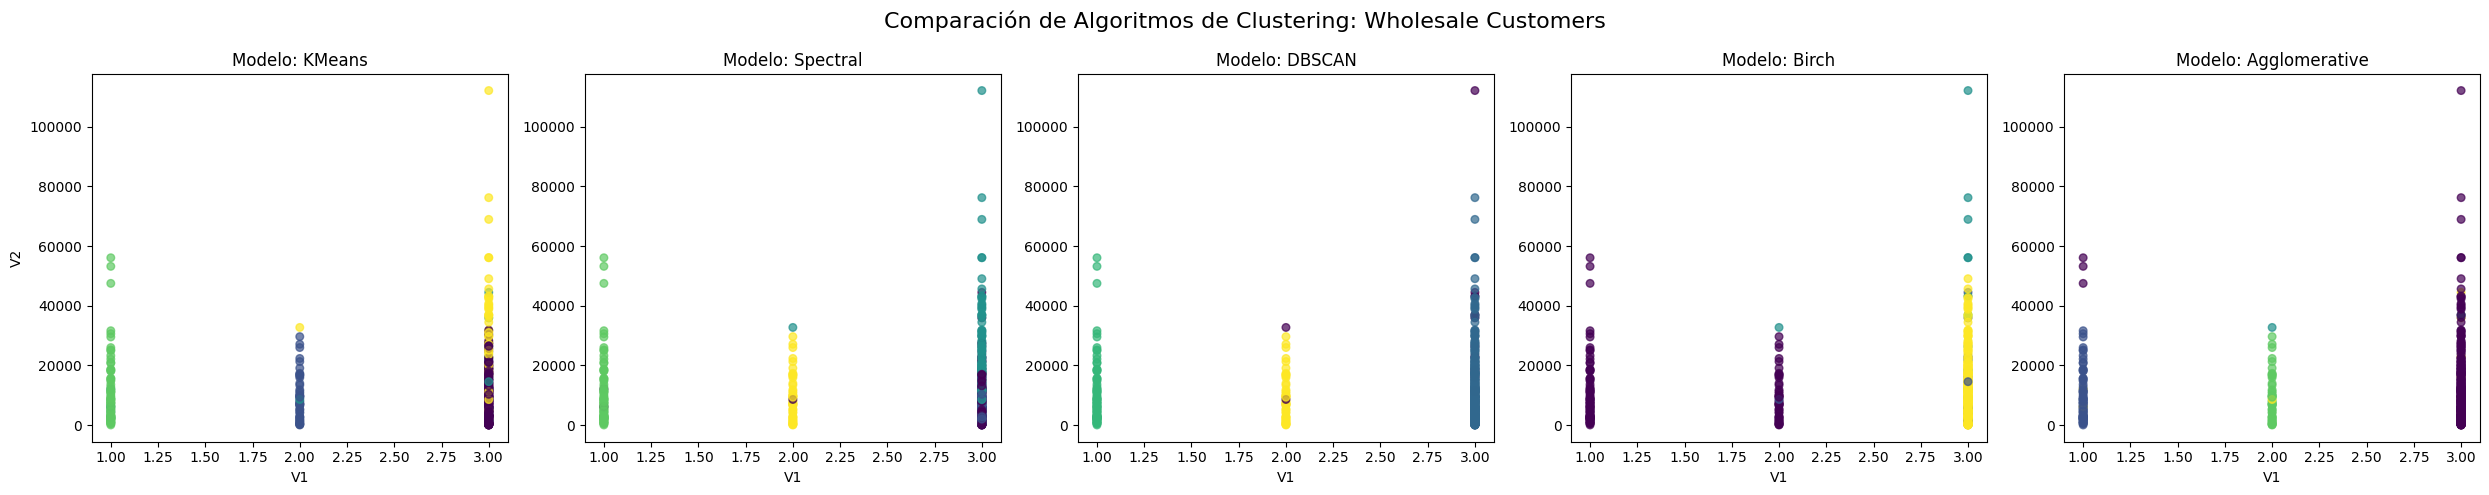

Aplicando clustering al dataset de Seeds...


c:\Users\adhev\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


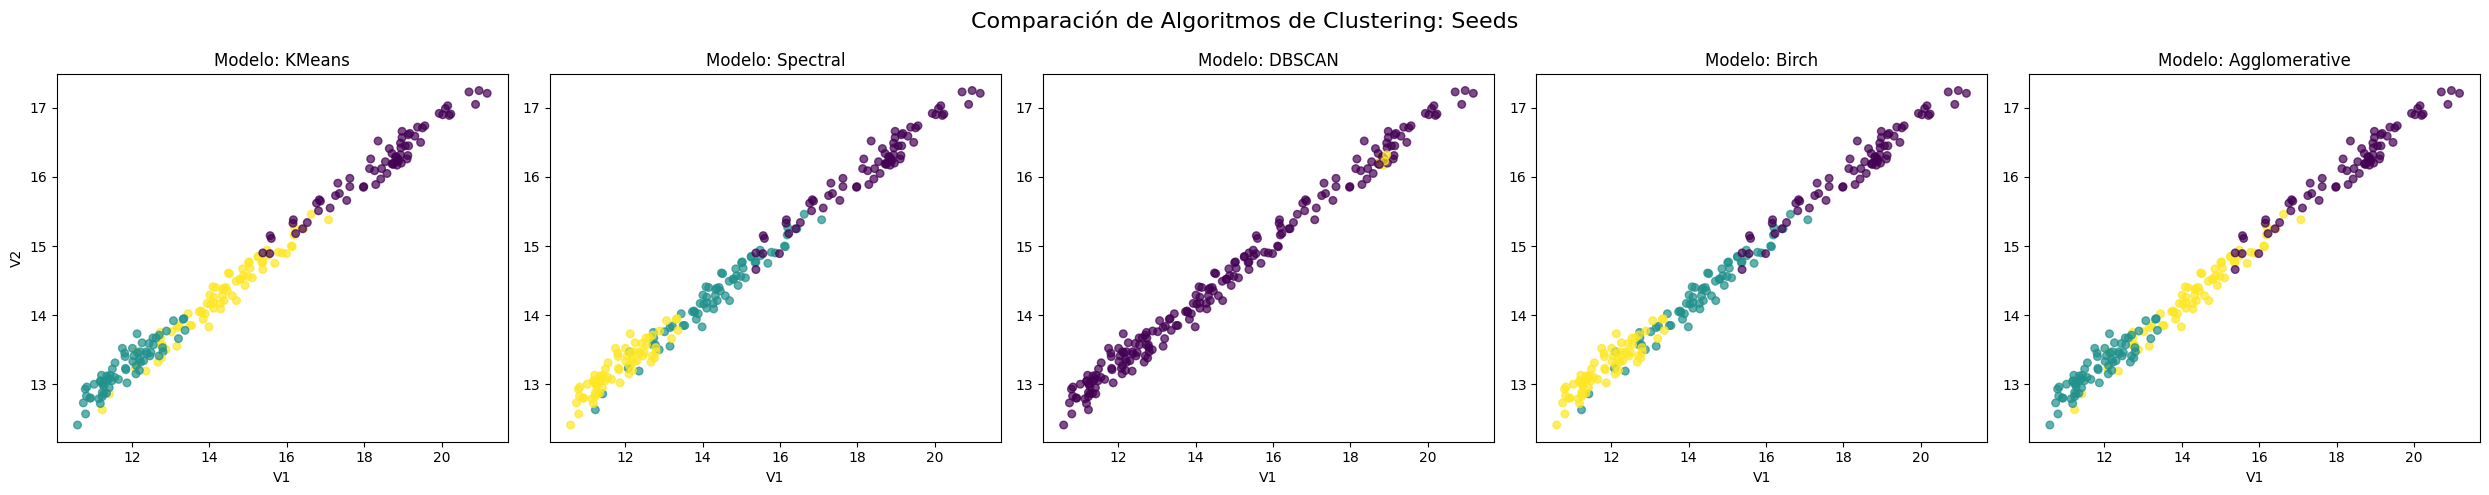

In [8]:
"""
Aplicar clustering a los datasets y visualizar los resultados.
"""

print("Aplicando clustering al dataset de Mall Customers...")
resultados_mall = aplicar_clustering(df_mall, n_clusters=5, columnas_ignorar='CustomerID', eps=3, min_samples=5)
graficar_comparacion(resultados_mall, "Mall Customers")

print("Aplicando clustering al dataset de Wholesale Customers...")
resultados_wholesale = aplicar_clustering(df_wholesale, n_clusters=5, columnas_ignorar='Channel', eps=3, min_samples=5)
graficar_comparacion(resultados_wholesale, "Wholesale Customers")

print("Aplicando clustering al dataset de Seeds...")
resultados_seeds = aplicar_clustering(df_seeds, n_clusters=3, columnas_ignorar='id', eps=0.5, min_samples=5)
graficar_comparacion(resultados_seeds, "Seeds")

#### Parte 2

Aplicando clustering al dataset de Wine Quality...


c:\Users\adhev\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


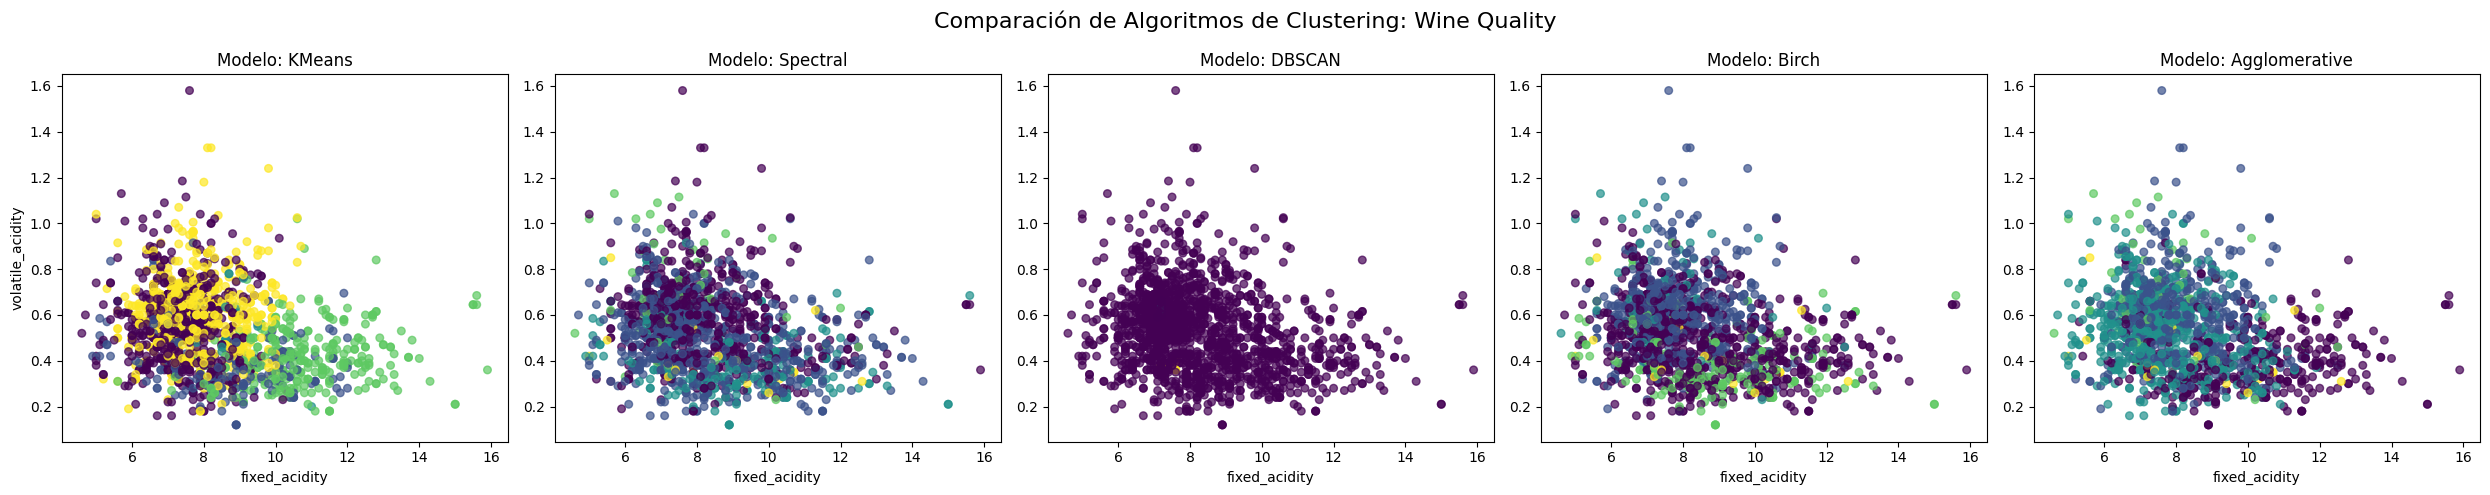

Aplicando clustering al dataset de Online Shoppers Intention...


c:\Users\adhev\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


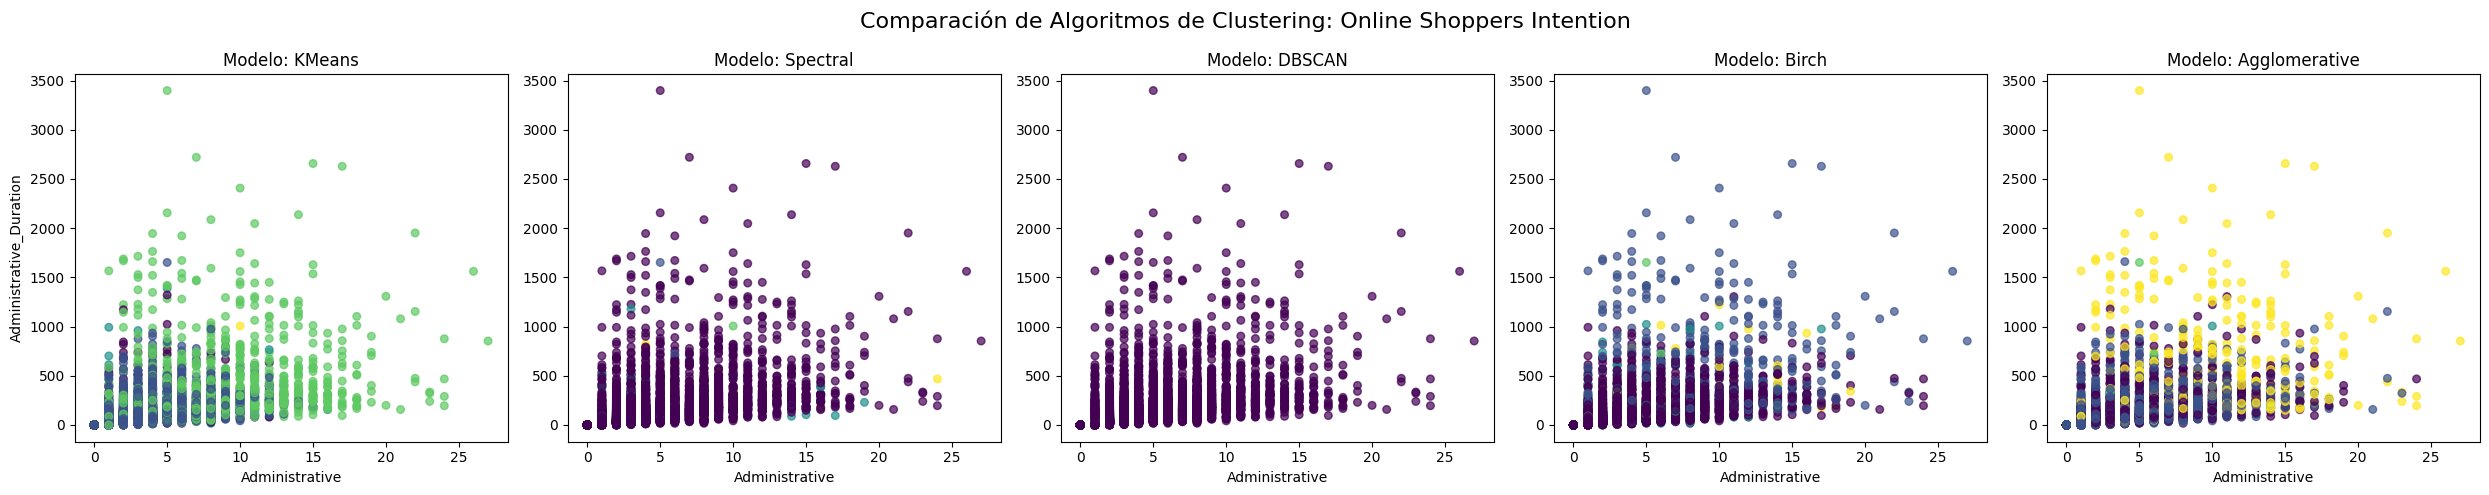

Aplicando clustering al dataset de Student Performance...


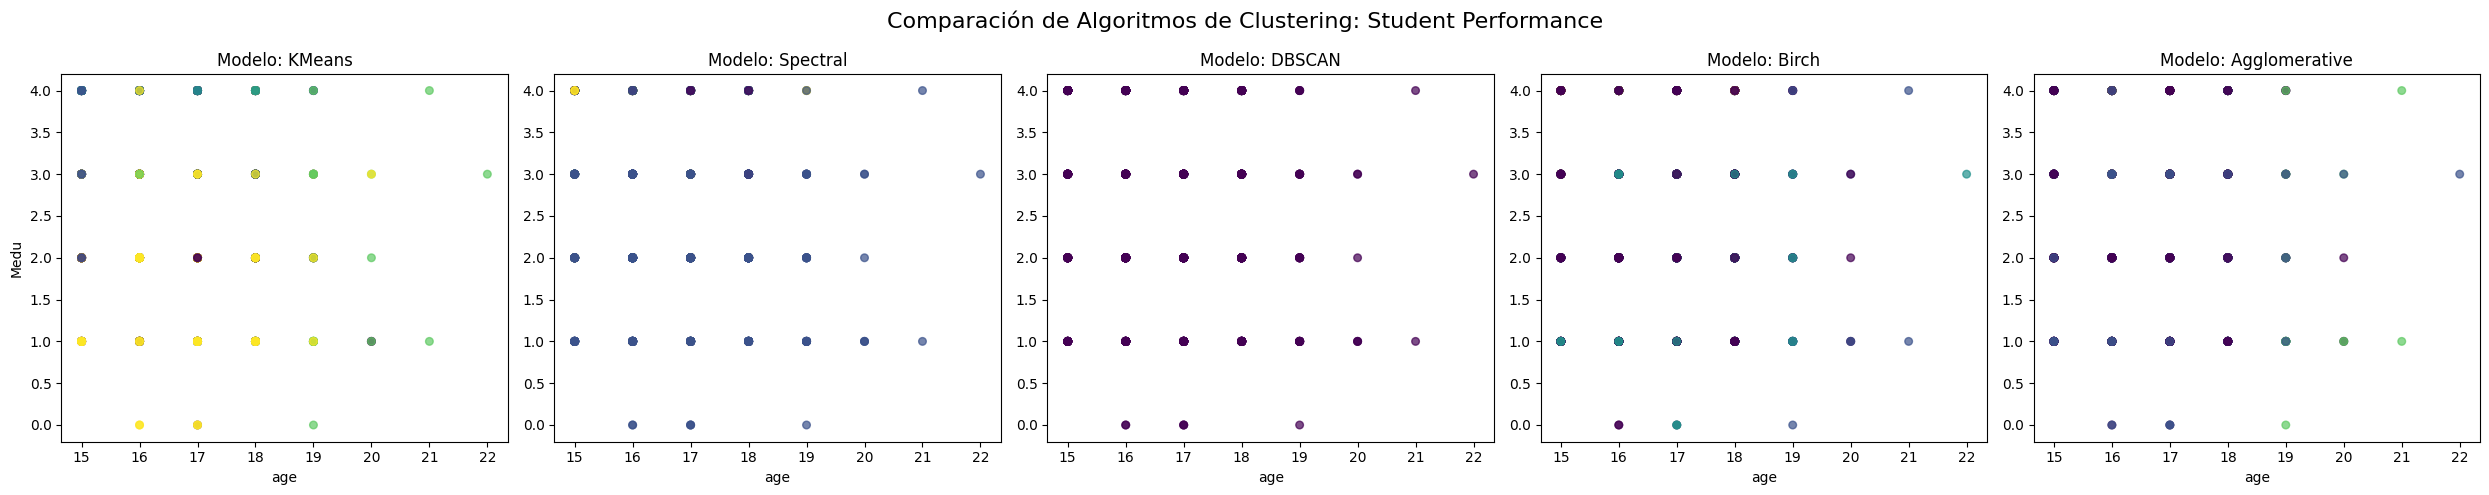

In [9]:
"""
Aplicar clustering a los datasets y visualizar los resultados.
"""

print("Aplicando clustering al dataset de Wine Quality...")
resultados_wine = aplicar_clustering(df_wine, n_clusters=5, columnas_ignorar='quality', eps=0.5, min_samples=5)
graficar_comparacion(resultados_wine, "Wine Quality")

print("Aplicando clustering al dataset de Online Shoppers Intention...")
resultados_shoppers = aplicar_clustering(df_shoppers, n_clusters=5, columnas_ignorar='Revenue', eps=0.5, min_samples=5)
graficar_comparacion(resultados_shoppers, "Online Shoppers Intention")

print("Aplicando clustering al dataset de Student Performance...")
resultados_student = aplicar_clustering(df_student, n_clusters=5, columnas_ignorar='G3', eps=0.5, min_samples=5)
graficar_comparacion(resultados_student, "Student Performance")

In [10]:
"""
Utilizar los resultados de wine, shoppers y student para entrenar un modelo de regresión y clasificación respectivamente.

wine_quality seran ambos regresión y clasifiacion
shoppers sera clasificación
student sera regresión
"""
import numpy as np
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, 
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split

def entrenar_modelo_regresion(X_train, y_train, X_test, y_test):
    modelo = RandomForestRegressor(random_state=42)
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    
    mse = mean_squared_error(y_test, predicciones)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predicciones)
    r2 = r2_score(y_test, predicciones)
    
    # Evitar división por cero en MAPE
    y_test_safe = np.where(y_test == 0, 1e-10, y_test)
    mape = np.mean(np.abs((y_test - predicciones) / y_test_safe)) * 100  
    
    # MSLE real (usando logaritmos) para evitar errores matemáticos
    msle = np.mean(np.square(np.log1p(np.maximum(y_test, 0)) - np.log1p(np.maximum(predicciones, 0))))

    # Mostrar grafica de regresión con línea de tendencia
    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, predicciones, alpha=0.7)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Valores Reales')
    plt.ylabel('Predicciones')
    plt.title('Regresión: Valores Reales vs Predicciones')
    plt.tight_layout()
    plt.show()
    
    return predicciones, mse, rmse, mae, r2, mape, msle

def entrenar_modelo_clasificacion(X_train, y_train, X_test, y_test):
    modelo = MLPClassifier(random_state=42, max_iter=1000)
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    
    accuracy = accuracy_score(y_test, predicciones)
    precision = precision_score(y_test, predicciones, average='weighted', zero_division=0)
    recall = recall_score(y_test, predicciones, average='weighted', zero_division=0)
    f1 = f1_score(y_test, predicciones, average='weighted', zero_division=0)
    
    cm = confusion_matrix(y_test, predicciones)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo.classes_)
    
    return predicciones, accuracy, precision, recall, f1, cm, disp

# --- FUNCIÓN PRINCIPAL DE EVALUACIÓN ACTUALIZADA ---
def evaluar_con_clusters(resultados_clustering, df_original, columna_target, tarea, nombre_dataset):
    print(f"\n{'='*50}\nEVALUANDO DATASET: {nombre_dataset} ({tarea.upper()})\n{'='*50}")
    
    # Recuperamos la variable 'y' original respetando el índice
    y = df_original.loc[resultados_clustering.index, columna_target]
    
    modelos_clustering = ['Cluster_KMeans', 'Cluster_Spectral', 'Cluster_DBSCAN', 'Cluster_Birch', 'Cluster_Agglomerative']
    
    for col_cluster in modelos_clustering:
        print(f"\n--- Usando características originales + {col_cluster} ---")
        
        columnas_a_ignorar = [c for c in modelos_clustering if c != col_cluster]
        X = resultados_clustering.drop(columns=columnas_a_ignorar)
        
        if tarea in ['regresion', 'ambas']:
            # FORZAMOS 'y' A NUMÉRICO para que las operaciones matemáticas de error funcionen
            y_reg = pd.to_numeric(y, errors='coerce')
            
            X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)
            
            pred, mse, rmse, mae, r2, mape, msle = entrenar_modelo_regresion(X_train, y_train, X_test, y_test)

            # Mostrar métricas de regresión por tabla
            metrics_reg = {
                "MSE": mse,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "MAPE": mape,
                "MSLE": msle
            }
            df_metricas_reg = pd.DataFrame([metrics_reg])
            print(df_metricas_reg)

        if tarea in ['clasificacion', 'ambas']:
            # FORZAMOS 'y' A TEXTO para que la clasificación lo trate como etiquetas
            y_class = y.astype(str)
            
            X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)
            
            pred, acc, prec, rec, f1, cm, disp = entrenar_modelo_clasificacion(X_train_c, y_train_c, X_test_c, y_test_c)

            # Mostrar métricas de clasificación por tabla
            metrics_class = {
                "Accuracy": acc,
                "Precision": prec,
                "Recall": rec,
                "F1-Score": f1
            }

            df_metricas_class = pd.DataFrame([metrics_class])
            print(df_metricas_class)

            # Mostrar la matriz de confusión
            plt.figure(figsize=(6, 4))
            fig, ax = plt.subplots(figsize=(6, 4))
            disp.plot(cmap='Blues', ax=ax, xticks_rotation='vertical')
            plt.title(f'Matriz de Confusión - {col_cluster}\nDataset: {nombre_dataset}')
            plt.tight_layout()
            plt.show()

Generando clusters para Wine Quality...

EVALUANDO DATASET: Wine Quality (AMBAS)

--- Usando características originales + Cluster_KMeans ---


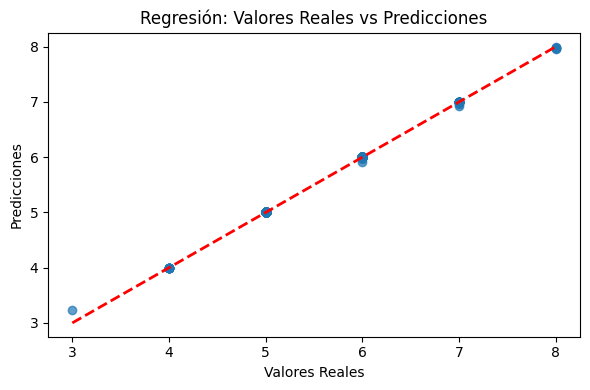

        MSE     RMSE       MAE        R2      MAPE      MSLE
0  0.000235  0.01532  0.001906  0.999641  0.041034  0.000011
   Accuracy  Precision  Recall  F1-Score
0       1.0        1.0     1.0       1.0


<Figure size 600x400 with 0 Axes>

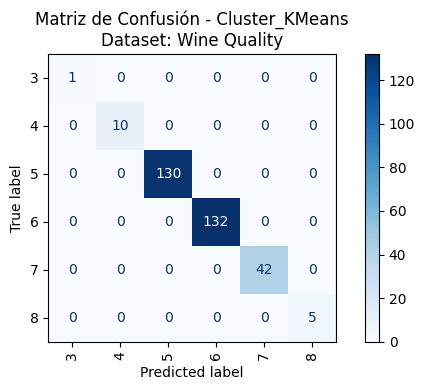


--- Usando características originales + Cluster_Spectral ---


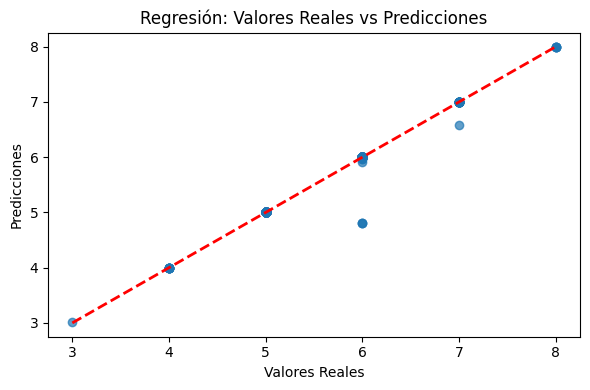

        MSE     RMSE       MAE        R2      MAPE      MSLE
0  0.014057  0.11856  0.013031  0.978491  0.214658  0.000341
   Accuracy  Precision  Recall  F1-Score
0       1.0        1.0     1.0       1.0


<Figure size 600x400 with 0 Axes>

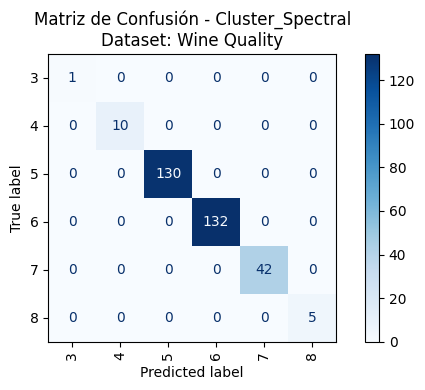


--- Usando características originales + Cluster_DBSCAN ---


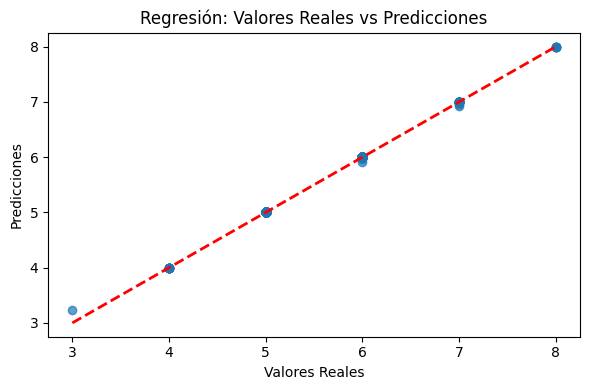

        MSE     RMSE       MAE        R2      MAPE      MSLE
0  0.000218  0.01478  0.001469  0.999666  0.035565  0.000011
   Accuracy  Precision  Recall  F1-Score
0       1.0        1.0     1.0       1.0


<Figure size 600x400 with 0 Axes>

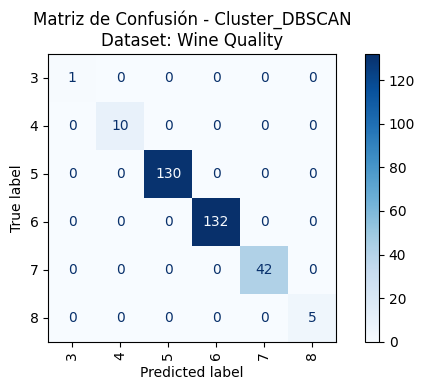


--- Usando características originales + Cluster_Birch ---


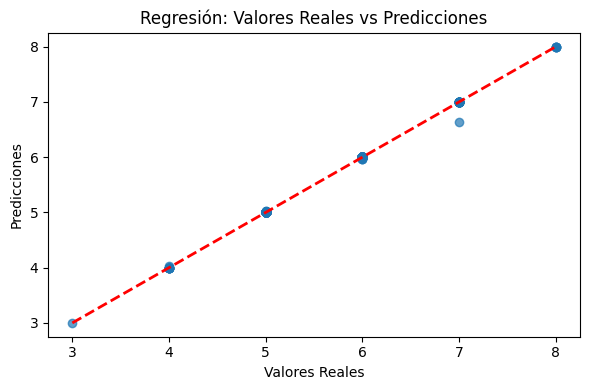

        MSE      RMSE       MAE        R2      MAPE      MSLE
0  0.000419  0.020463  0.001625  0.999359  0.025603  0.000007
   Accuracy  Precision  Recall  F1-Score
0       1.0        1.0     1.0       1.0


<Figure size 600x400 with 0 Axes>

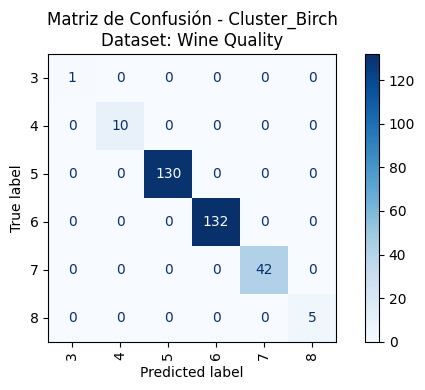


--- Usando características originales + Cluster_Agglomerative ---


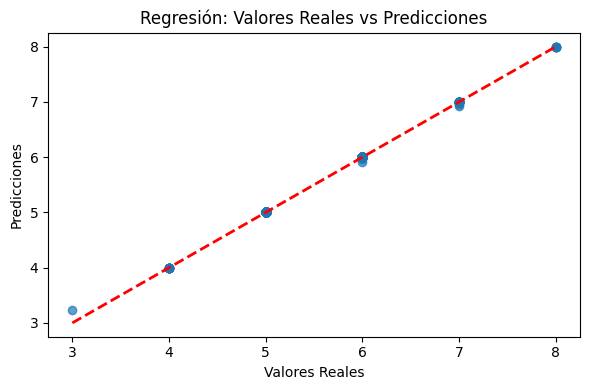

        MSE     RMSE       MAE        R2      MAPE      MSLE
0  0.000218  0.01478  0.001469  0.999666  0.035565  0.000011
   Accuracy  Precision  Recall  F1-Score
0       1.0        1.0     1.0       1.0


<Figure size 600x400 with 0 Axes>

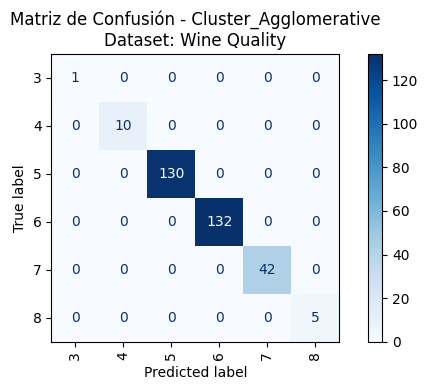

Generando clusters para Online Shoppers Intention...

EVALUANDO DATASET: Online Shoppers (CLASIFICACION)

--- Usando características originales + Cluster_KMeans ---
   Accuracy  Precision    Recall  F1-Score
0  0.845093   0.859232  0.845093  0.850889


<Figure size 600x400 with 0 Axes>

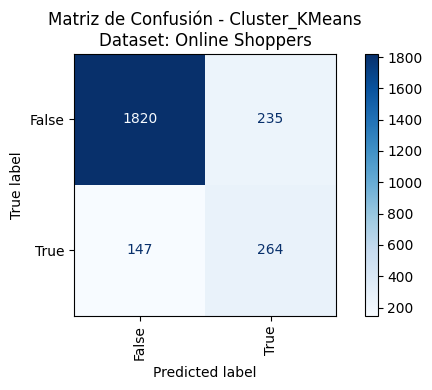


--- Usando características originales + Cluster_Spectral ---
   Accuracy  Precision    Recall  F1-Score
0  0.874696    0.86224  0.874696  0.860526


<Figure size 600x400 with 0 Axes>

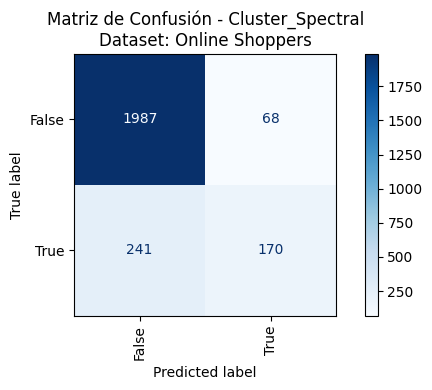


--- Usando características originales + Cluster_DBSCAN ---
   Accuracy  Precision   Recall  F1-Score
0   0.86983   0.866982  0.86983  0.840189


<Figure size 600x400 with 0 Axes>

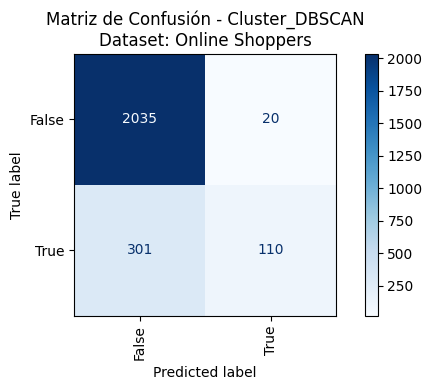


--- Usando características originales + Cluster_Birch ---
   Accuracy  Precision    Recall  F1-Score
0  0.870235   0.858091  0.870235  0.848741


<Figure size 600x400 with 0 Axes>

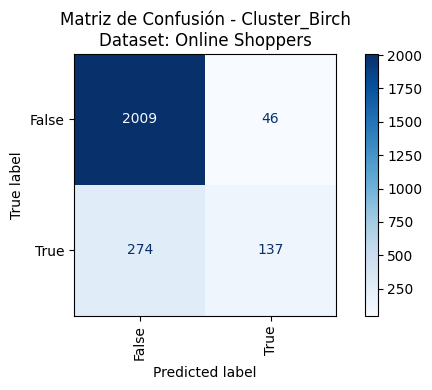


--- Usando características originales + Cluster_Agglomerative ---
   Accuracy  Precision    Recall  F1-Score
0  0.852798   0.870317  0.852798  0.859512


<Figure size 600x400 with 0 Axes>

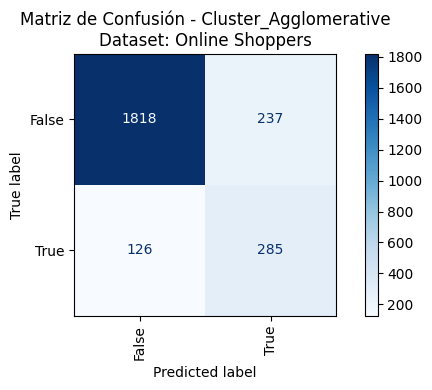

Generando clusters para Student Performance...

EVALUANDO DATASET: Student Performance (REGRESION)

--- Usando características originales + Cluster_KMeans ---


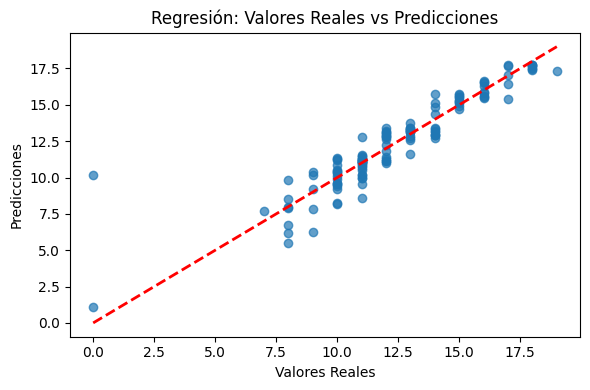

        MSE      RMSE       MAE        R2          MAPE      MSLE
0  1.562415  1.249966  0.757769  0.839781  8.707692e+10  0.055415

--- Usando características originales + Cluster_Spectral ---


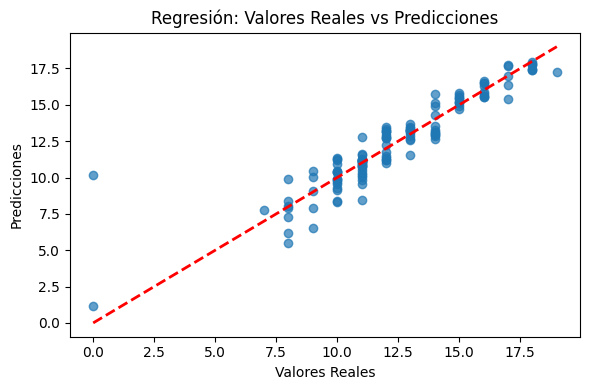

        MSE      RMSE       MAE        R2          MAPE      MSLE
0  1.558059  1.248222  0.751769  0.840227  8.753846e+10  0.055553

--- Usando características originales + Cluster_DBSCAN ---


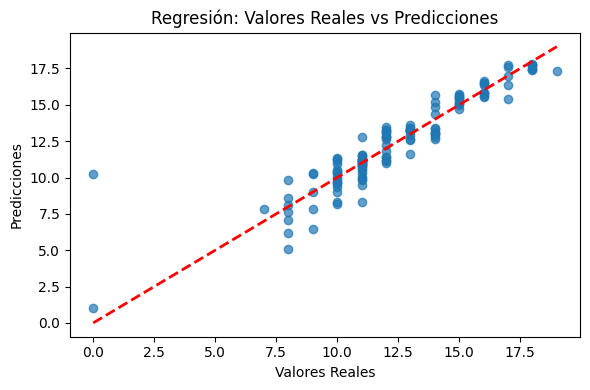

        MSE      RMSE       MAE        R2          MAPE     MSLE
0  1.588323  1.260287  0.761385  0.837124  8.669231e+10  0.05542

--- Usando características originales + Cluster_Birch ---


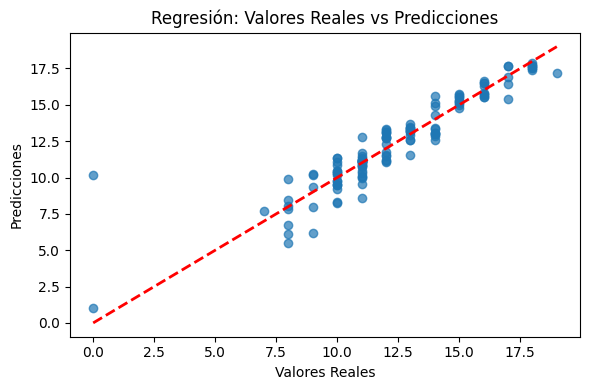

        MSE      RMSE       MAE        R2          MAPE      MSLE
0  1.547755  1.244088  0.751077  0.841284  8.592308e+10  0.054721

--- Usando características originales + Cluster_Agglomerative ---


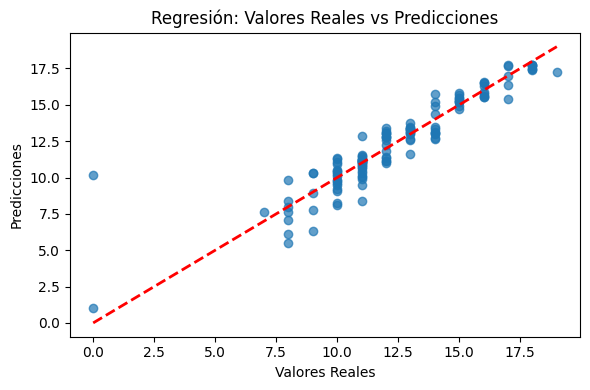

        MSE      RMSE       MAE        R2          MAPE      MSLE
0  1.573085  1.254227  0.761846  0.838686  8.615385e+10  0.054912


In [11]:
"""
Entrenar modelos de regresión y clasificación con los conjuntos de datos wine, shoppers y student.
"""

# 1. WINE QUALITY (Ambas tareas)
print("Generando clusters para Wine Quality...")
columna_target_wine = df_wine.columns[-1]
evaluar_con_clusters(resultados_wine, df_wine, columna_target_wine, 'ambas', 'Wine Quality')

# 2. ONLINE SHOPPERS (Clasificación)
print("Generando clusters para Online Shoppers Intention...")
evaluar_con_clusters(resultados_shoppers, df_shoppers, 'Revenue', 'clasificacion', 'Online Shoppers')

# 3. STUDENT PERFORMANCE (Regresión)
# Asumimos que predecimos G3 (nota final). Podemos ignorar G1 y G2 si queremos que sea un desafío real.
print("Generando clusters para Student Performance...")
evaluar_con_clusters(resultados_student, df_student, 'G3', 'regresion', 'Student Performance')
